In [2]:
!pip install pandas openpyxl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_s = pd.read_excel("Dataset Académico Parches en Servidores.xlsx", skiprows=3)
df_v = pd.read_excel("Dataset Académico Parches en Servidores.xlsx", skiprows=3, sheet_name=1)



In [3]:
# Exploratory data Analysis
print("Dimensions of data Servidores: ")
print(df_s.shape)
print("NaN Analysis")
print(df_s.isna())
df_s.isna().sum() / len(df_s) * 100
print("=====================================================================")

print("Dimensions of data Vulnerabilidades: ")
print(df_v.shape)
print("NaN Analysis")
print(df_v.isna())
print("=====================================================================")
df_v.isna().sum() / len(df_v) * 100
print("Df.unique Servidores: ")
print(df_s.nunique())
print("")
print("Df.unique Vulnerabilidades ")
print(df_v.nunique())

Dimensions of data Servidores: 
(246, 17)
NaN Analysis
     ServerID  OSFamily  OSLifecycle  InfrastructureType  AssetType  \
0       False     False        False               False      False   
1       False     False        False               False      False   
2       False     False        False               False      False   
3       False     False        False               False      False   
4       False     False        False               False      False   
..        ...       ...          ...                 ...        ...   
241     False     False        False               False      False   
242     False     False        False               False      False   
243     False     False        False               False      False   
244     False     False        False               False      False   
245     False     False        False               False      False   

     FunctionalRole  Environment  RegionGroup  AssetCriticality  \
0             False      

Servidores (df_s) Shape: (246, 17) | Numeric Cols: 0
Vulnerabilidades (df_v) Shape: (3450, 20) | Numeric Cols: 1
No numeric columns to plot histograms for Servidores (df_s).


/var/folders/87/g5yrv6893jg53pjsvj02y3lh0000gn/T/ipykernel_22829/4158583882.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_s = df_s.select_dtypes(include=["object", "category"])
/var/folders/87/g5yrv6893jg53pjsvj02y3lh0000gn/T/ipykernel_22829/4158583882.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
Se

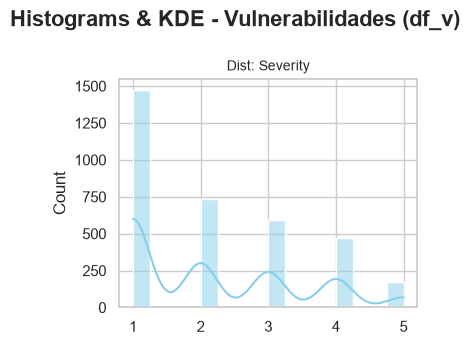

No numeric columns to plot boxplots for Servidores (df_s).


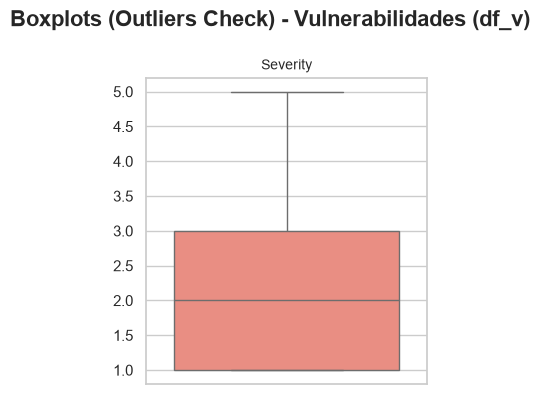

Not enough numeric columns for a correlation matrix in Servidores (df_s).
Not enough numeric columns for a correlation matrix in Vulnerabilidades (df_v).

--- Top Categories Distribution for Servidores (df_s) ---
Column 'ServerID' has high cardinality (246 unique values). Displaying top 12.


/var/folders/87/g5yrv6893jg53pjsvj02y3lh0000gn/T/ipykernel_22829/4158583882.py:132: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=["object", "category"]).columns


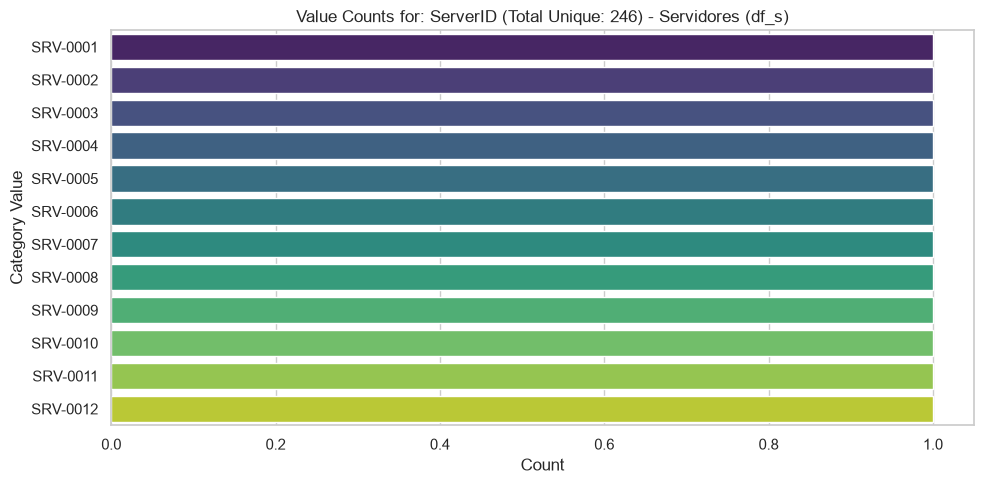

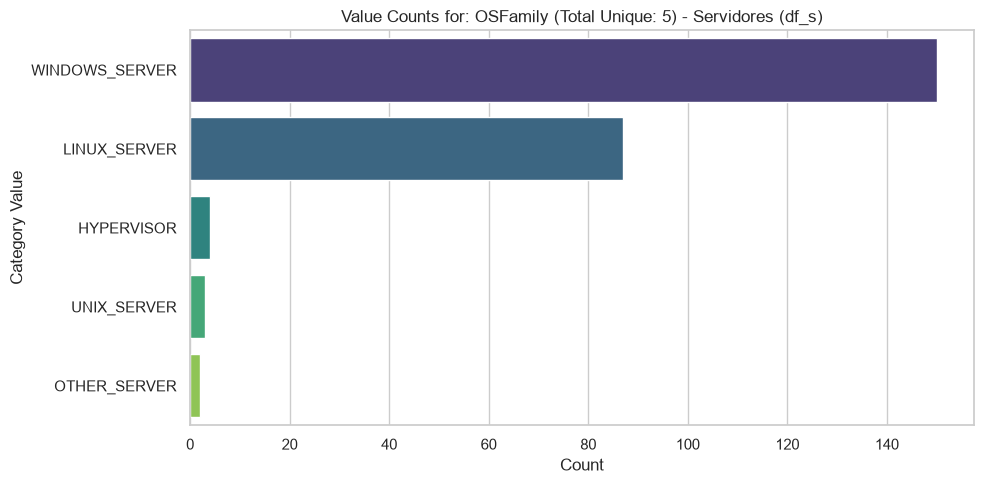

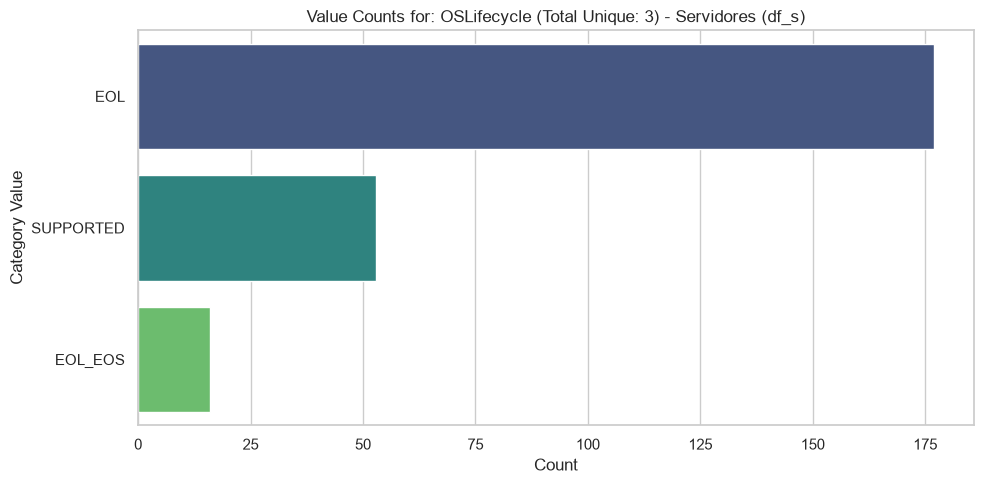

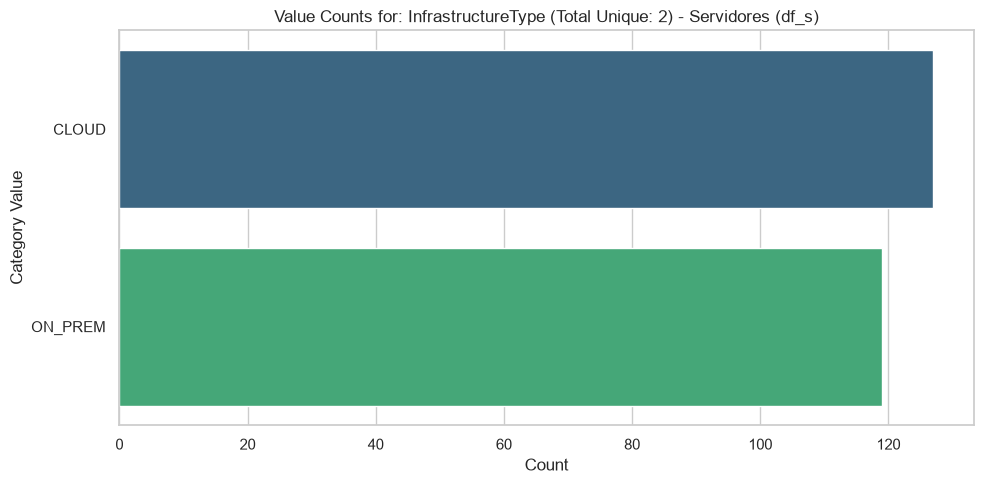

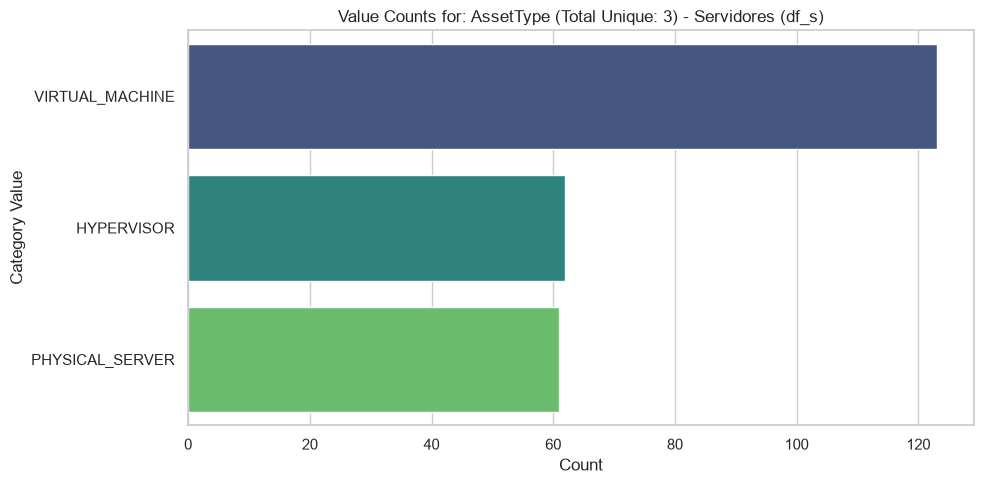

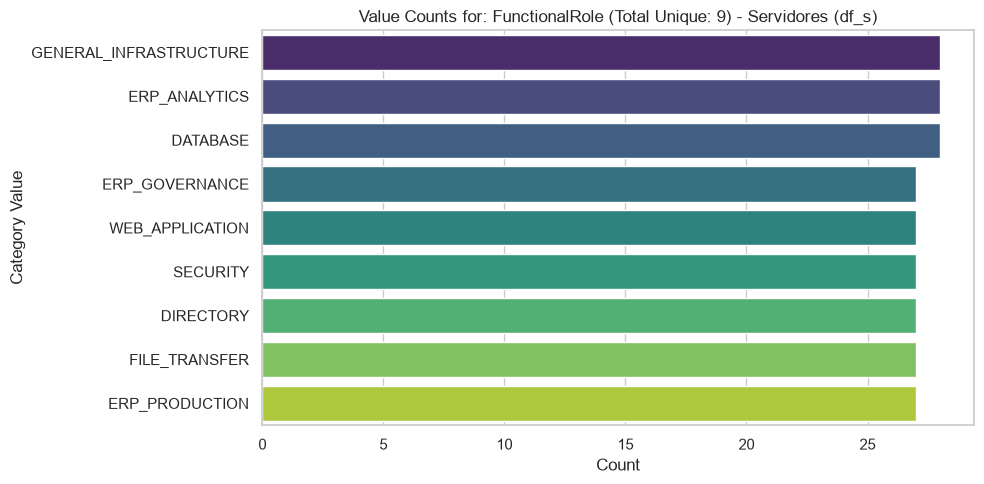

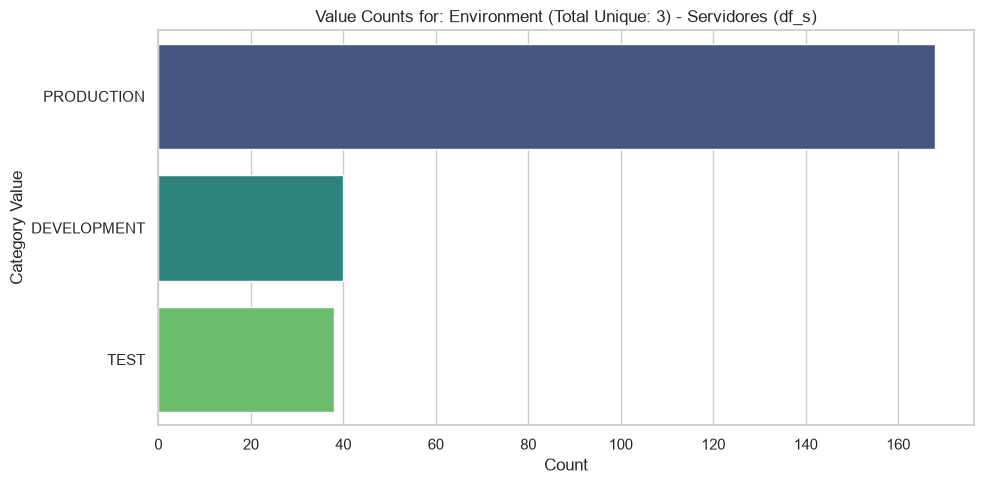

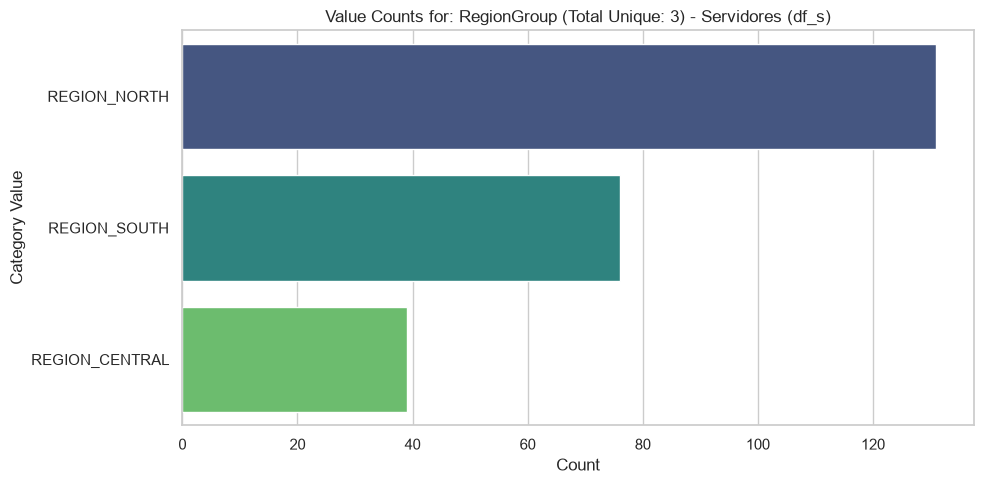

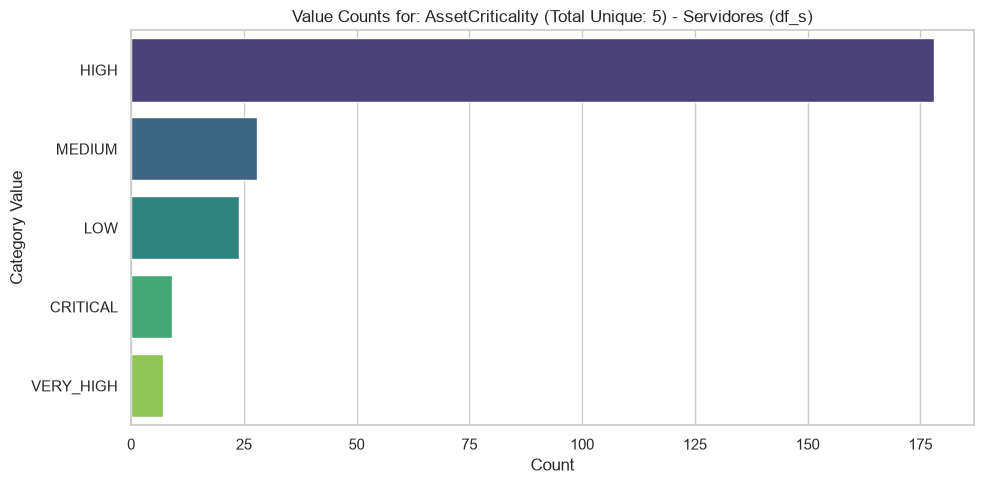

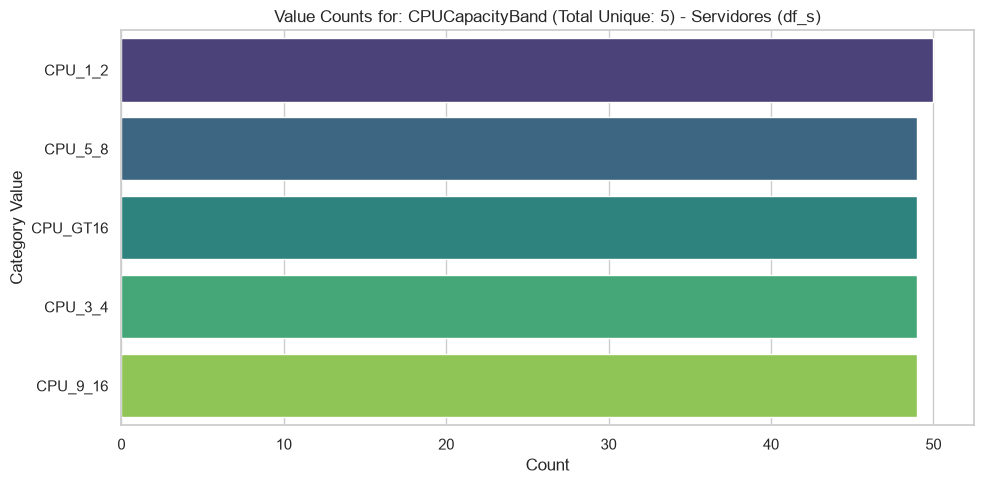

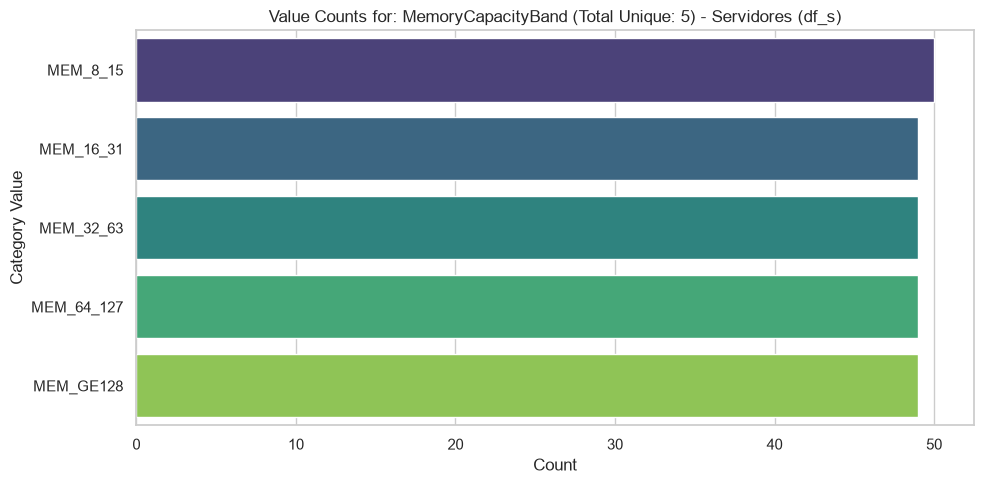

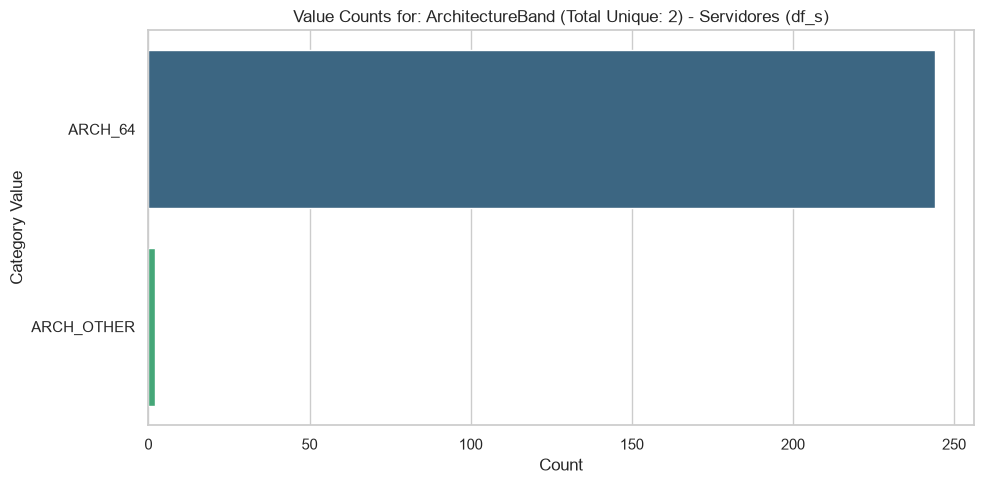

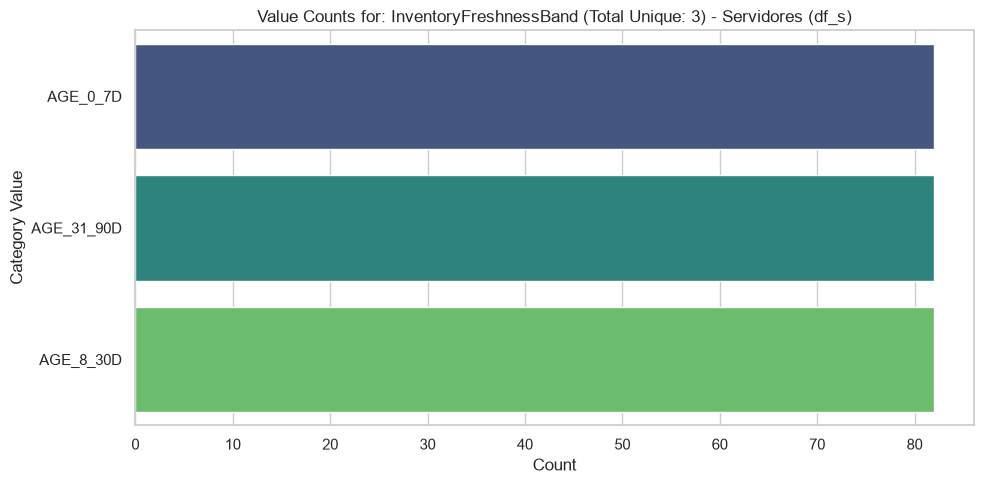

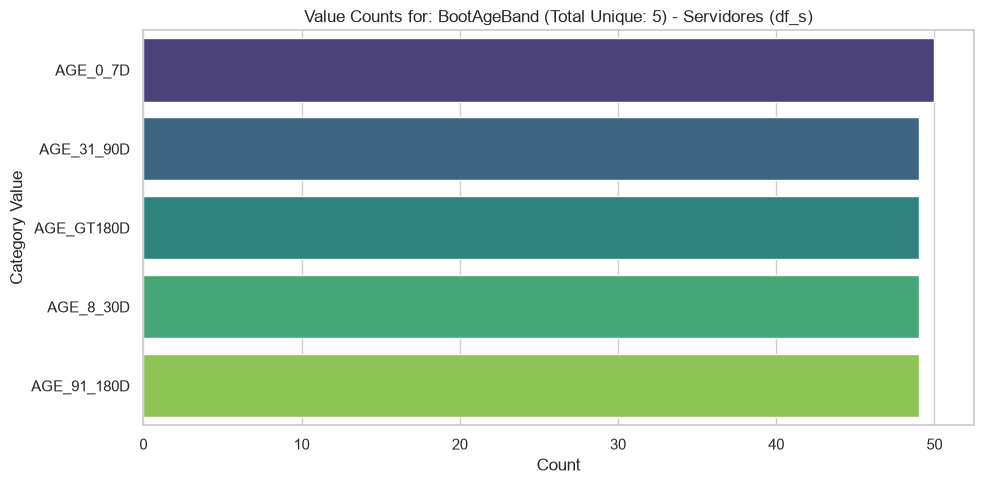

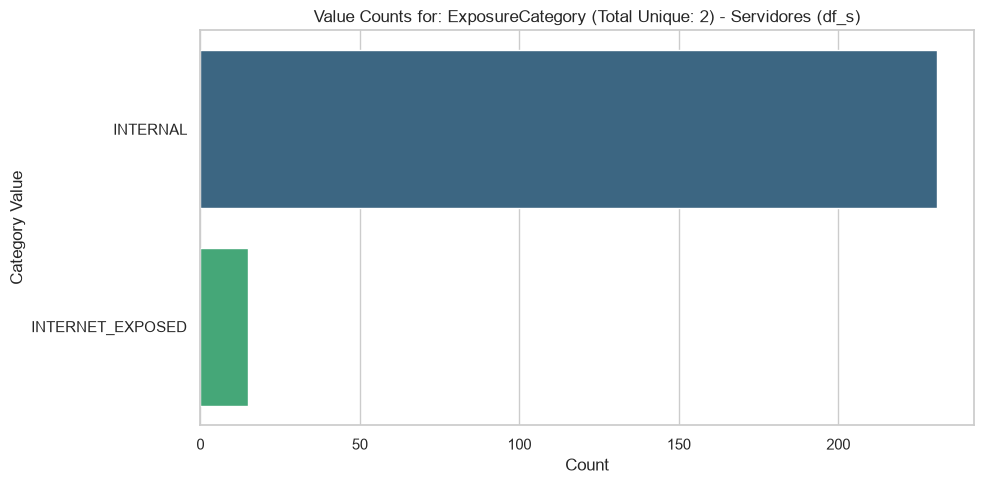

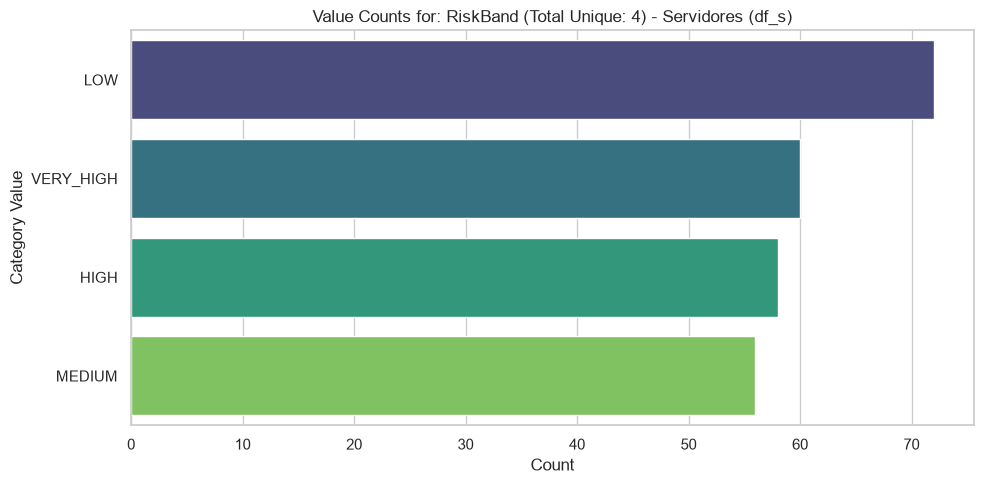

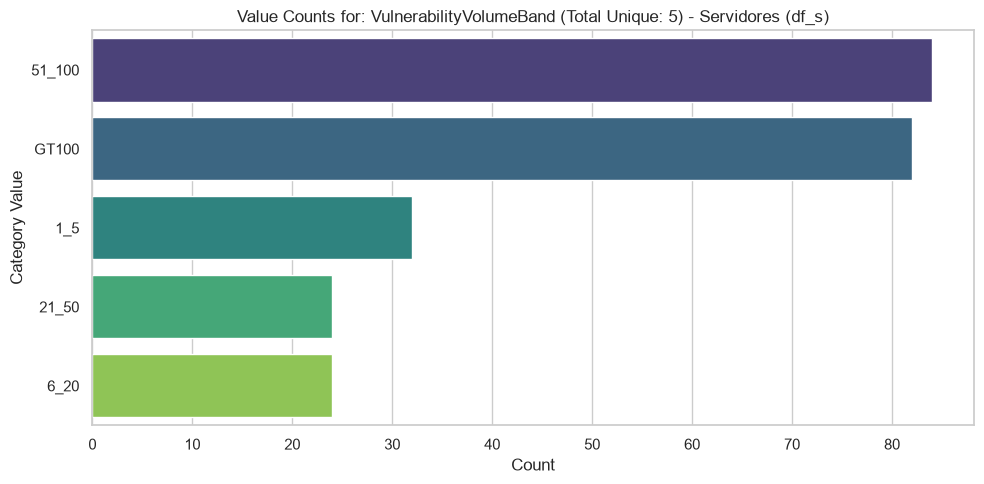


--- Top Categories Distribution for Vulnerabilidades (df_v) ---
Column 'FindingID' has high cardinality (3450 unique values). Displaying top 12.


/var/folders/87/g5yrv6893jg53pjsvj02y3lh0000gn/T/ipykernel_22829/4158583882.py:132: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=["object", "category"]).columns


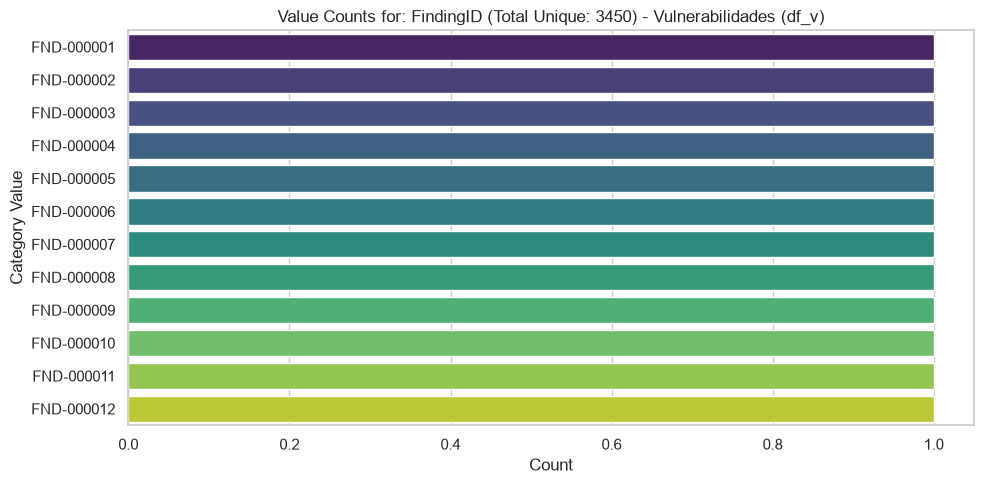

Column 'ServerID' has high cardinality (246 unique values). Displaying top 12.


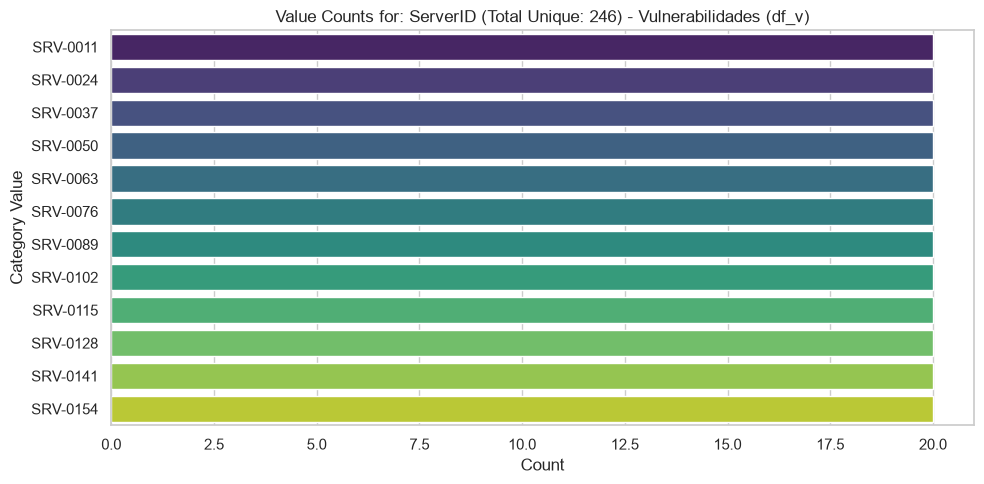

Column 'VulnerabilityTypeID' has high cardinality (120 unique values). Displaying top 12.


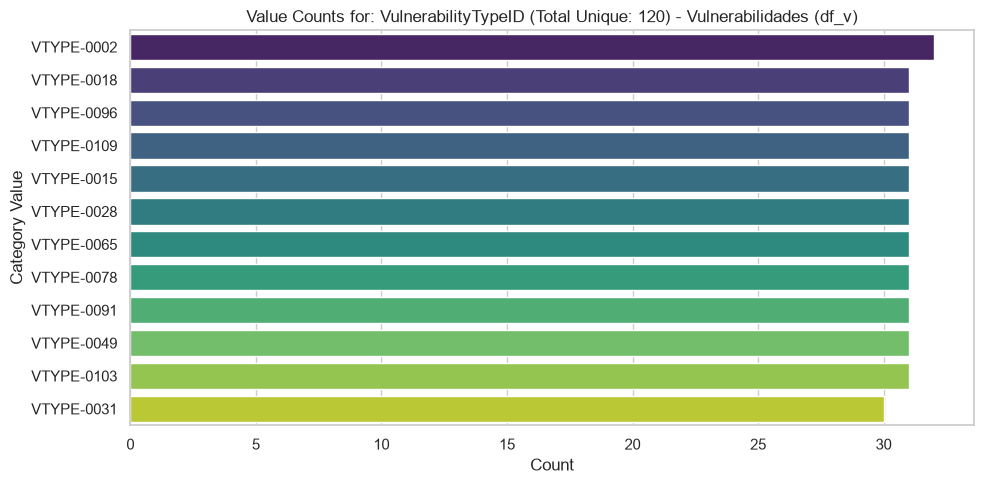

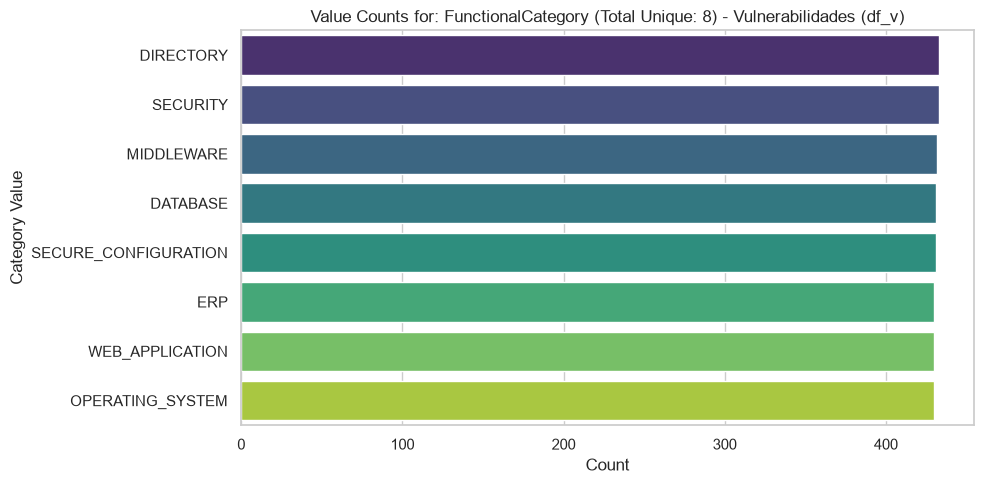

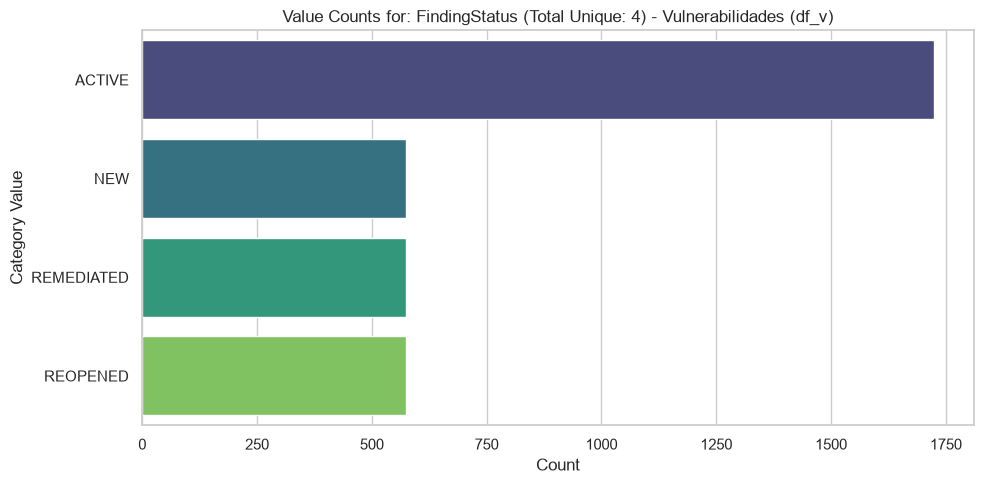

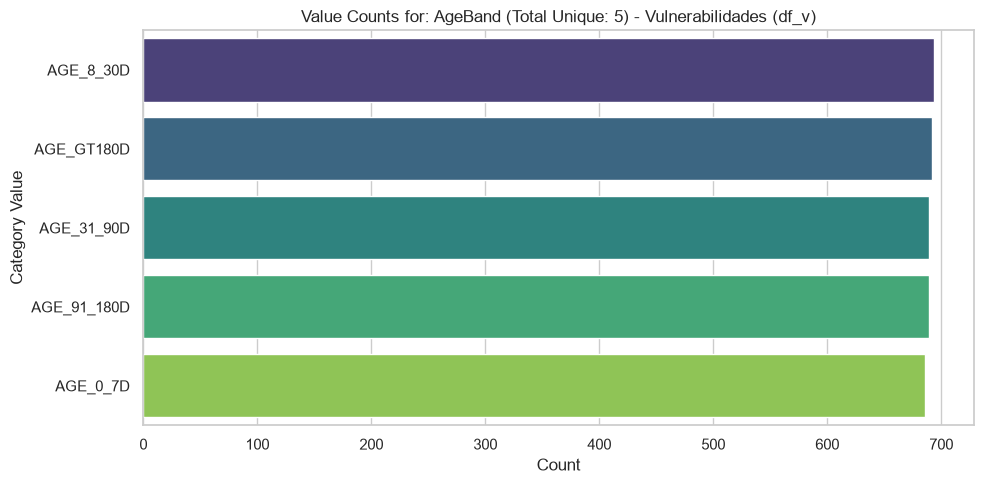

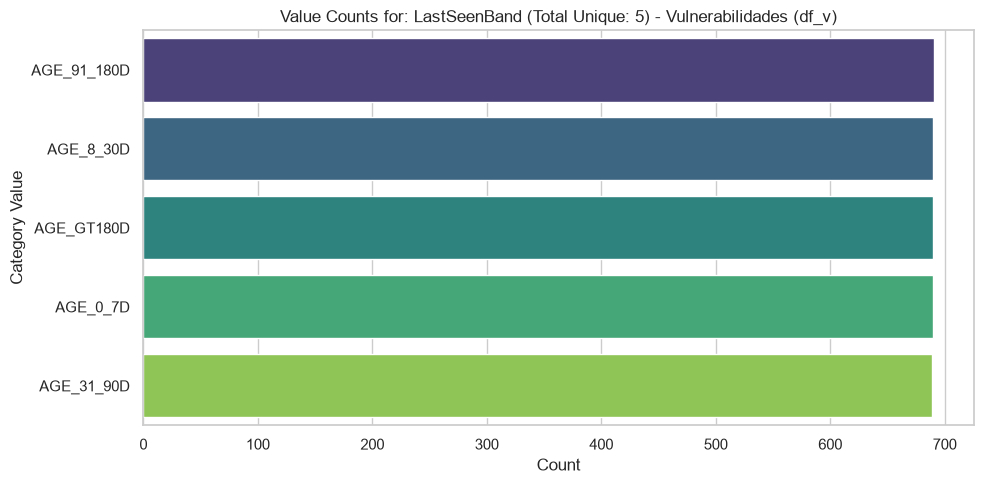

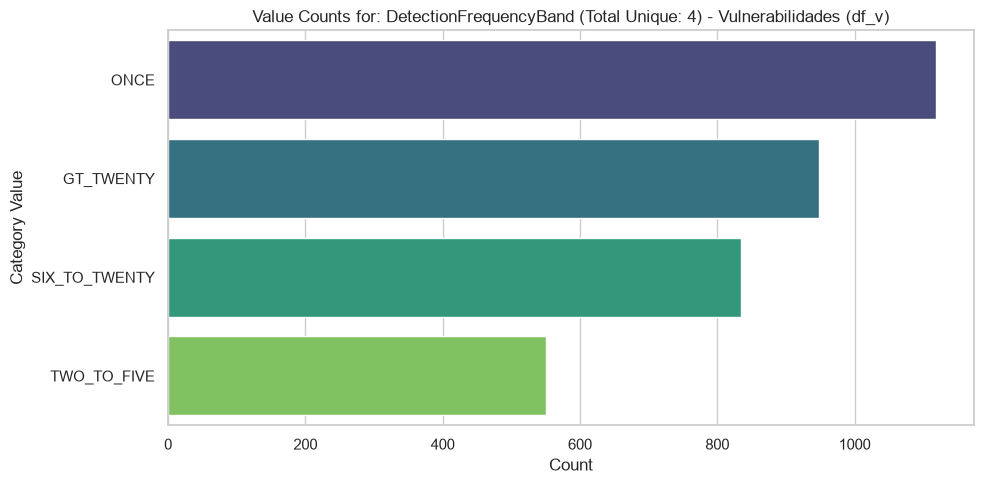

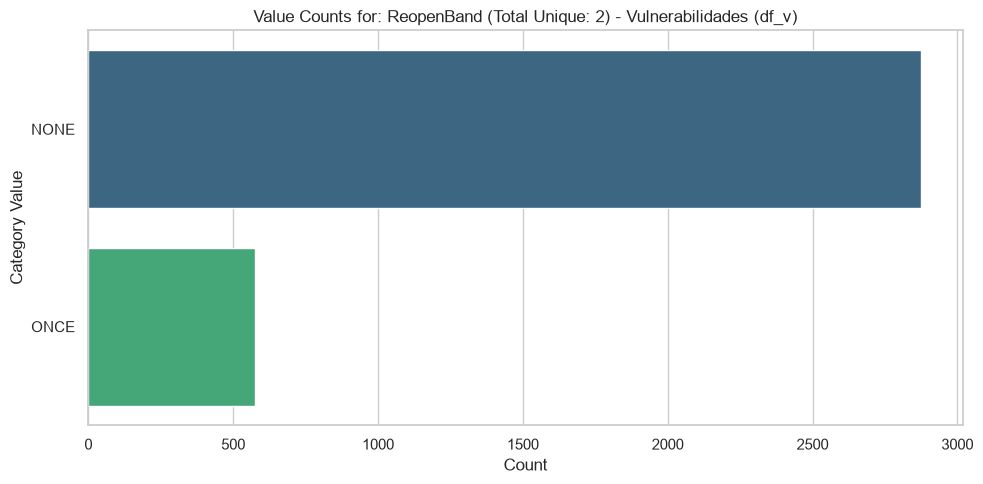

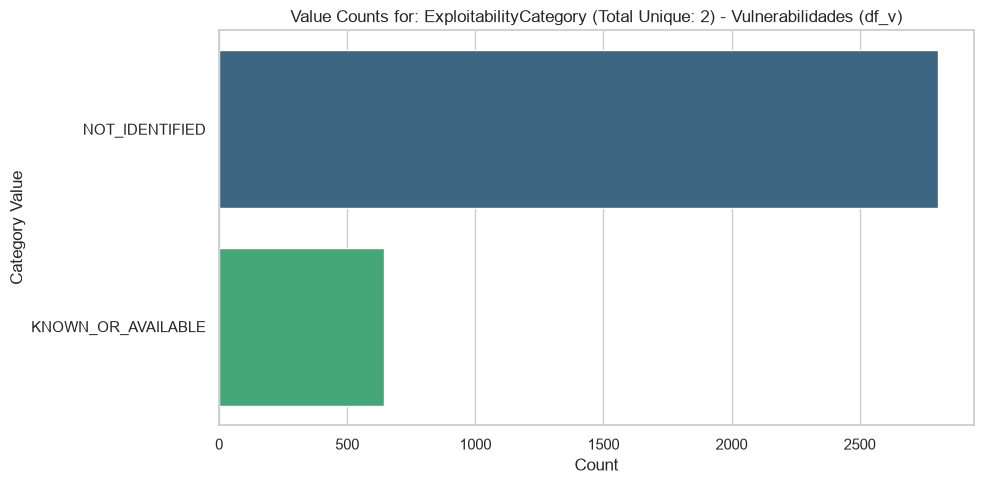

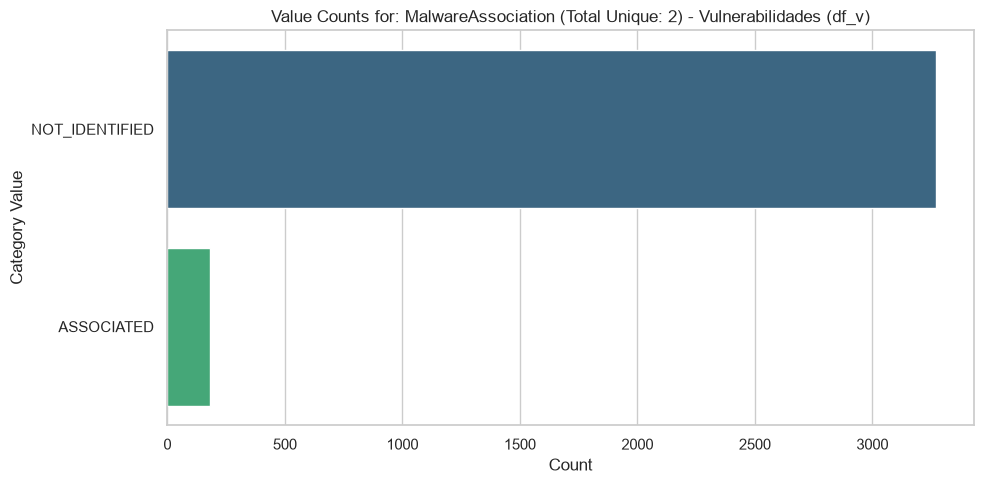

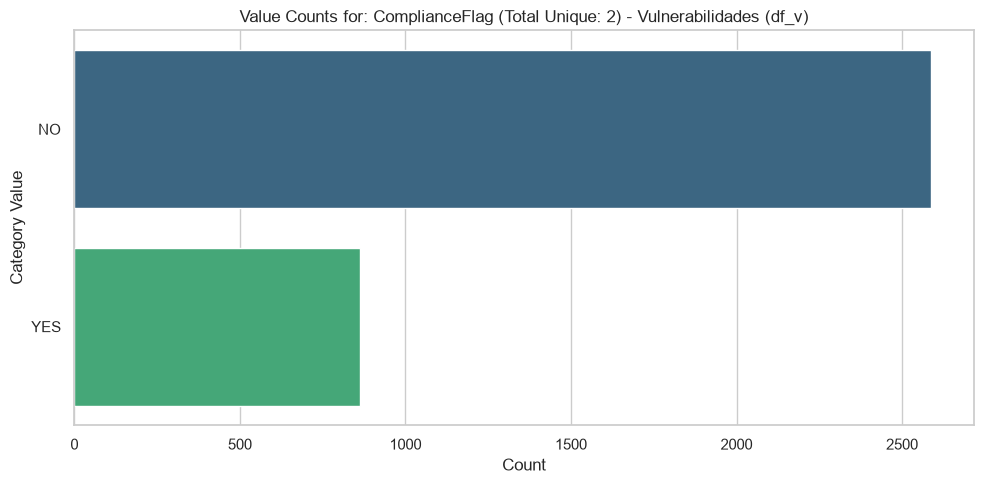

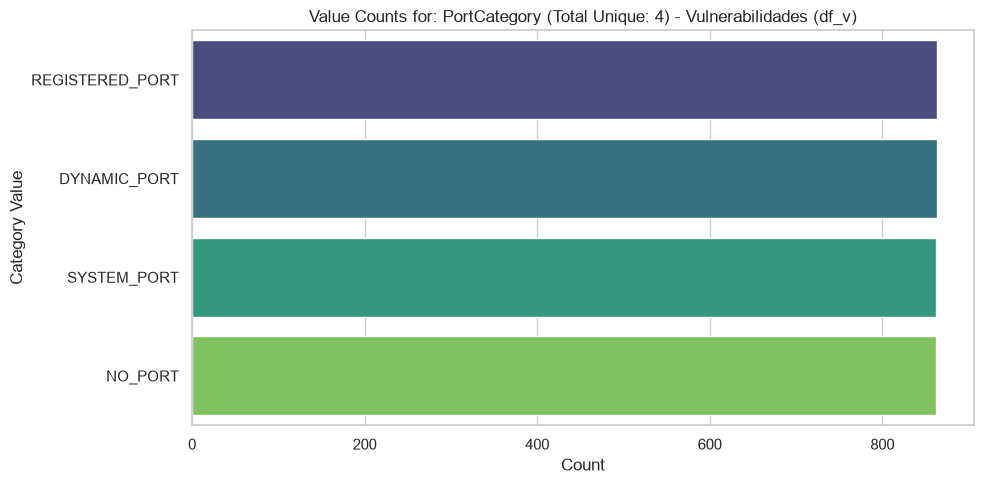

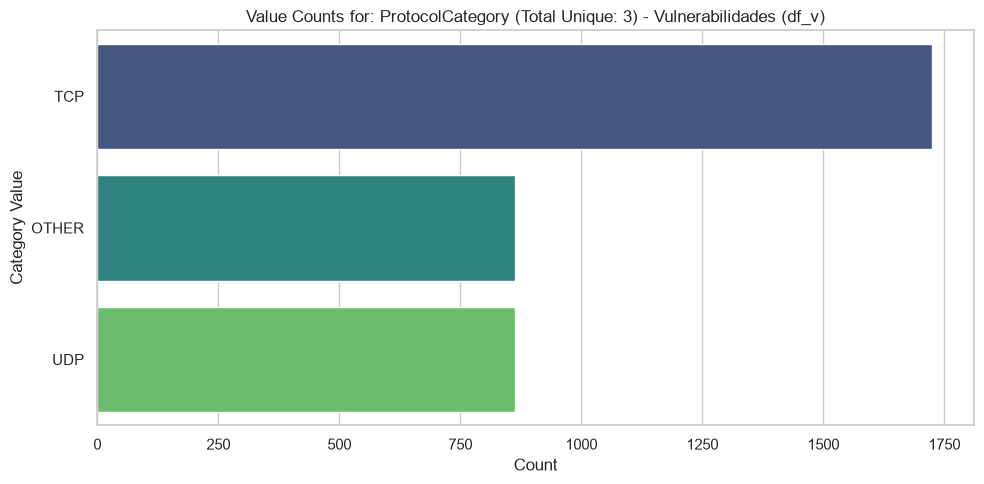

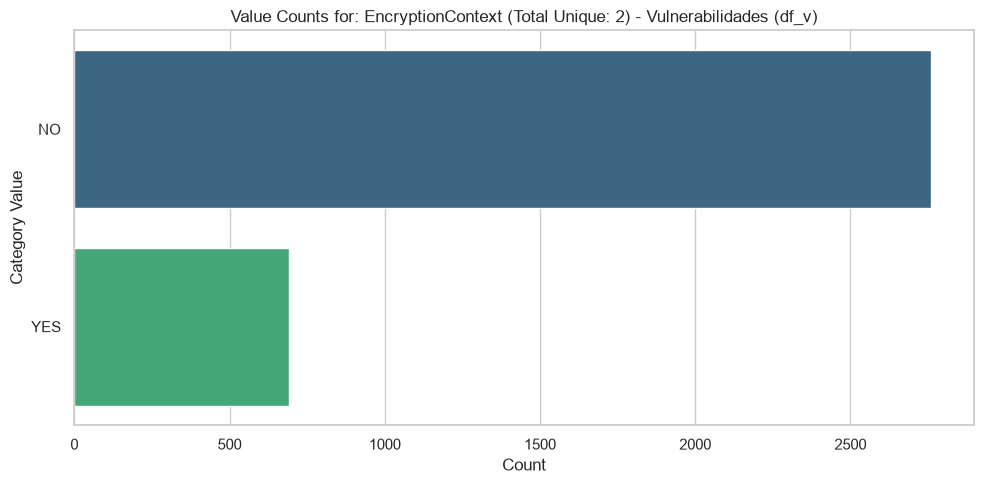

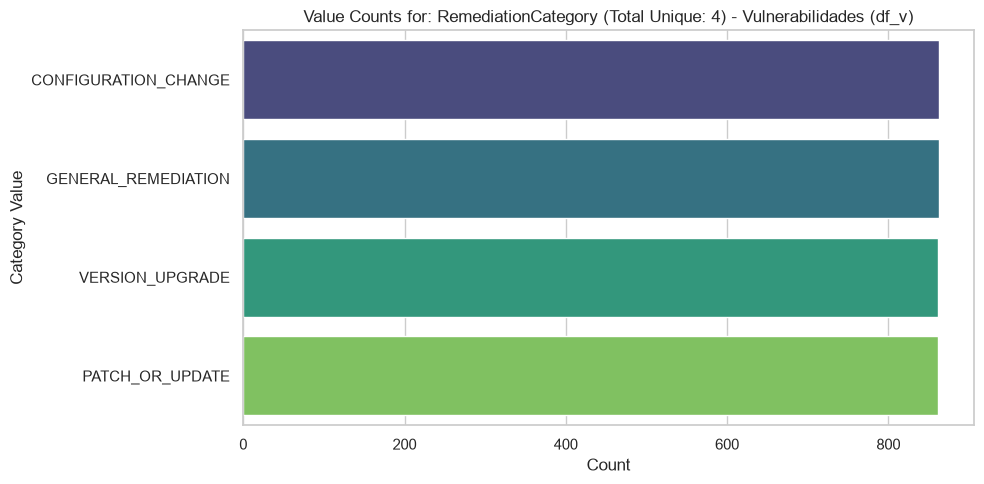

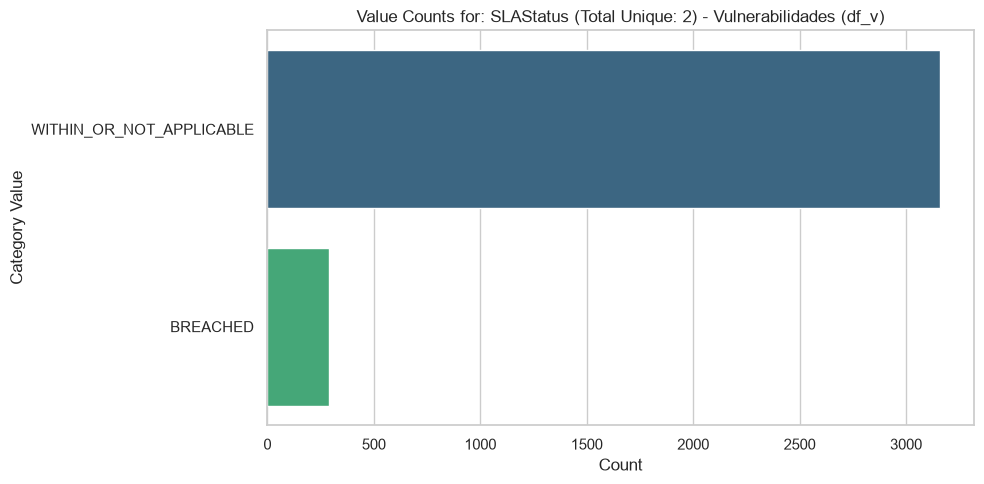

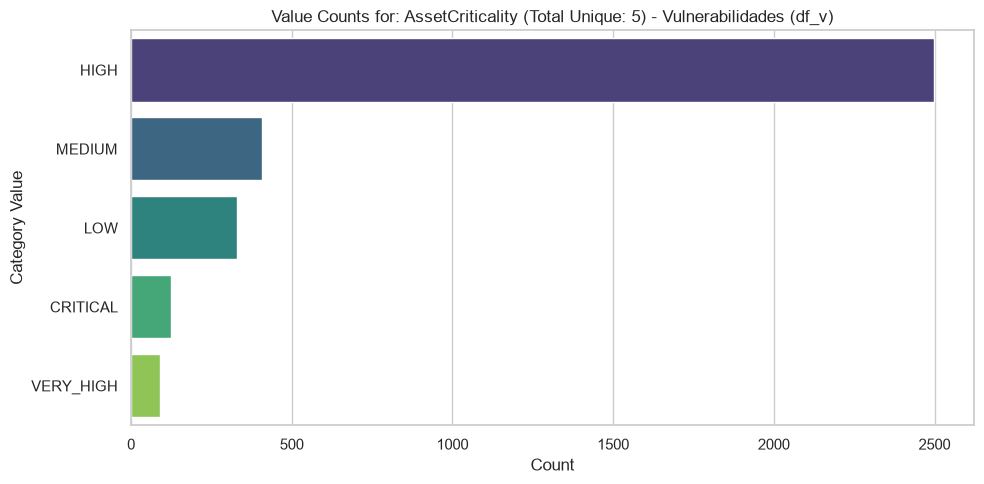

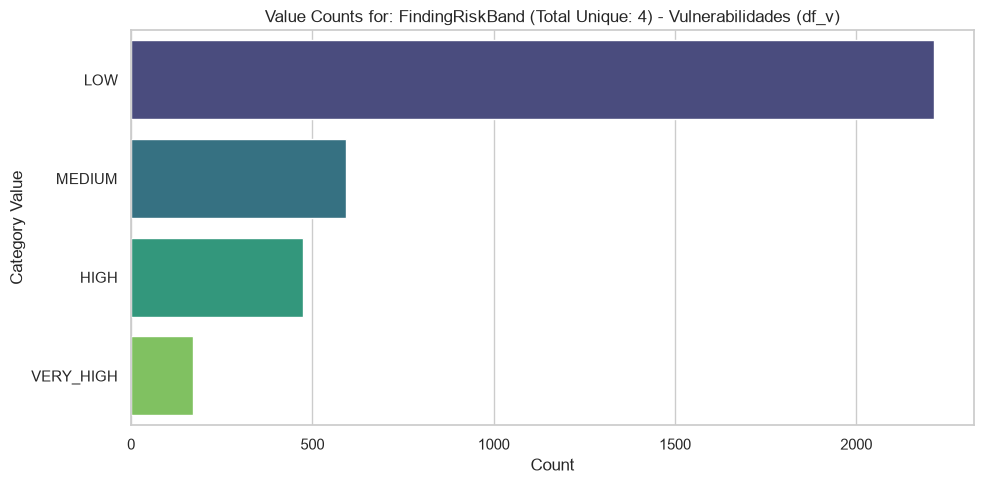

In [4]:

# Ensure plots look sharp and clean
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 8)

# =====================================================================
# 1. PREPARATION: ALIGNING BOTH DATAFRAMES
# =====================================================================
# Separate numeric and categorical columns for both datasets
numeric_s = df_s.select_dtypes(include=[np.number])
numeric_v = df_v.select_dtypes(include=[np.number])

categorical_s = df_s.select_dtypes(include=["object", "category"])
categorical_v = df_v.select_dtypes(include=["object", "category"])

print(f"Servidores (df_s) Shape: {df_s.shape} | Numeric Cols: {len(numeric_s.columns)}")
print(f"Vulnerabilidades (df_v) Shape: {df_v.shape} | Numeric Cols: {len(numeric_v.columns)}")


# =====================================================================
# 2. HISTOGRAMS (Distribution of Numeric Fields)
# =====================================================================
def plot_histograms(df, title):
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    if len(numeric_cols) == 0:
        print(f"No numeric columns to plot histograms for {title}.")
        return

    # Calculate grid size dynamically
    n_cols = min(3, len(numeric_cols))
    n_rows = int(np.ceil(len(numeric_cols) / n_cols))

    fig, axes = plt.subplots(
        n_rows, n_cols, figsize=(n_cols * 4, n_rows * 3.5), squeeze=False
    )
    axes = axes.flatten()

    for i, col in enumerate(numeric_cols):
        sns.histplot(df[col].dropna(), kde=True, ax=axes[i], color="skyblue")
        axes[i].set_title(f"Dist: {col}", fontsize=10)
        axes[i].set_xlabel("")

    # Hide unused subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.suptitle(f"Histograms & KDE - {title}", fontsize=16, weight="bold")
    plt.tight_layout()
    plt.show()


plot_histograms(df_s, "Servidores (df_s)")
plot_histograms(df_v, "Vulnerabilidades (df_v)")


# =====================================================================
# 3. BOXPLOTS (Outliers & Range Verification)
# =====================================================================
def plot_boxplots(df, title):
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    if len(numeric_cols) == 0:
        print(f"No numeric columns to plot boxplots for {title}.")
        return

    n_cols = min(4, len(numeric_cols))
    n_rows = int(np.ceil(len(numeric_cols) / n_cols))

    fig, axes = plt.subplots(
        n_rows, n_cols, figsize=(n_cols * 3.5, n_rows * 4), squeeze=False
    )
    axes = axes.flatten()

    for i, col in enumerate(numeric_cols):
        sns.boxplot(y=df[col], ax=axes[i], color="salmon")
        axes[i].set_title(col, fontsize=10)
        axes[i].set_ylabel("")

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.suptitle(f"Boxplots (Outliers Check) - {title}", fontsize=16, weight="bold")
    plt.tight_layout()
    plt.show()


plot_boxplots(df_s, "Servidores (df_s)")
plot_boxplots(df_v, "Vulnerabilidades (df_v)")


# =====================================================================
# 4. HEATMAPS & CORRELATION MAPS (Linear Dependencies)
# =====================================================================
def plot_correlation_map(df, title):
    numeric_df = df.select_dtypes(include=[np.number])

    if numeric_df.shape[1] < 2:
        print(f"Not enough numeric columns for a correlation matrix in {title}.")
        return

    # Compute correlation matrix
    corr_matrix = numeric_df.corr()

    # Generate a mask for the upper triangle (cleaner look)
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

    plt.figure(figsize=(10, 8))
    sns.heatmap(
        corr_matrix,
        mask=mask,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        square=True,
        linewidths=0.5,
        cbar_kws={"shrink": 0.8},
    )
    plt.title(f"Correlation Matrix Heatmap - {title}", fontsize=14, weight="bold")
    plt.tight_layout()
    plt.show()


plot_correlation_map(df_s, "Servidores (df_s)")
plot_correlation_map(df_v, "Vulnerabilidades (df_v)")


# =====================================================================
# 5. COMPLEX CATEGORICAL COLUMNS VISUALIZATION (High-Cardinality)
# =====================================================================
def plot_complex_categorical(df, title, max_categories=15):
    # Find categorical/string columns
    cat_cols = df.select_dtypes(include=["object", "category"]).columns

    if len(cat_cols) == 0:
        print(f"No categorical columns to map in {title}.")
        return

    print(f"\n--- Top Categories Distribution for {title} ---")

    for col in cat_cols:
        unique_counts = df[col].nunique()

        # If it has too many unique values (like unique IPs or Descriptions), limit display
        if unique_counts > max_categories:
            print(
                f"Column '{col}' has high cardinality ({unique_counts} unique values). Displaying top {max_categories}."
            )
            data_to_plot = df[col].value_counts().head(max_categories)
        else:
            data_to_plot = df[col].value_counts()

        if data_to_plot.empty:
            continue

        plt.figure(figsize=(10, 5))
        sns.barplot(
            x=data_to_plot.values,
            y=data_to_plot.index.astype(str),
            palette="viridis",
            hue=data_to_plot.index.astype(str),
            legend=False,
        )
        plt.title(
            f"Value Counts for: {col} (Total Unique: {unique_counts}) - {title}",
            fontsize=12,
        )
        plt.xlabel("Count")
        plt.ylabel("Category Value")
        plt.tight_layout()
        plt.show()


# Adjust max_categories depending on how many bars you want to see at most per plot
plot_complex_categorical(df_s, "Servidores (df_s)", max_categories=12)
plot_complex_categorical(df_v, "Vulnerabilidades (df_v)", max_categories=12)


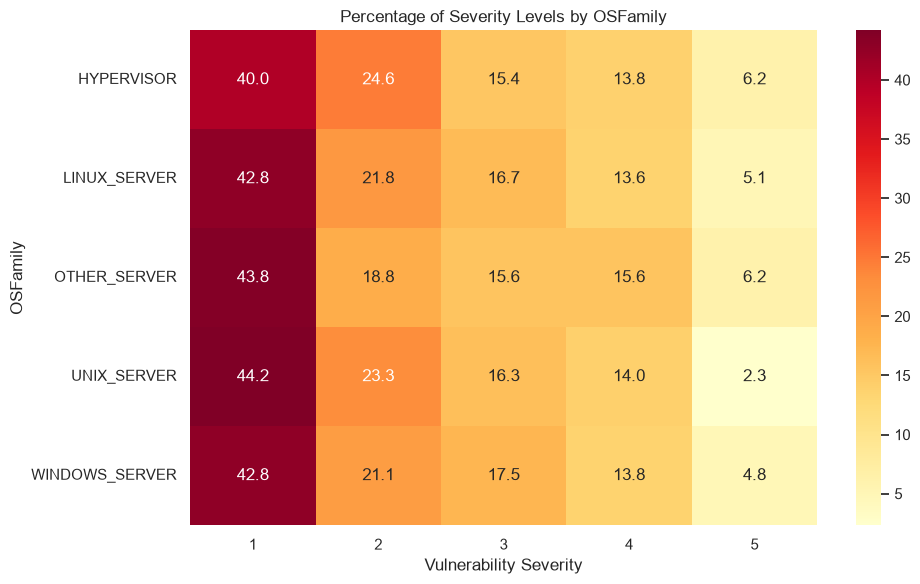

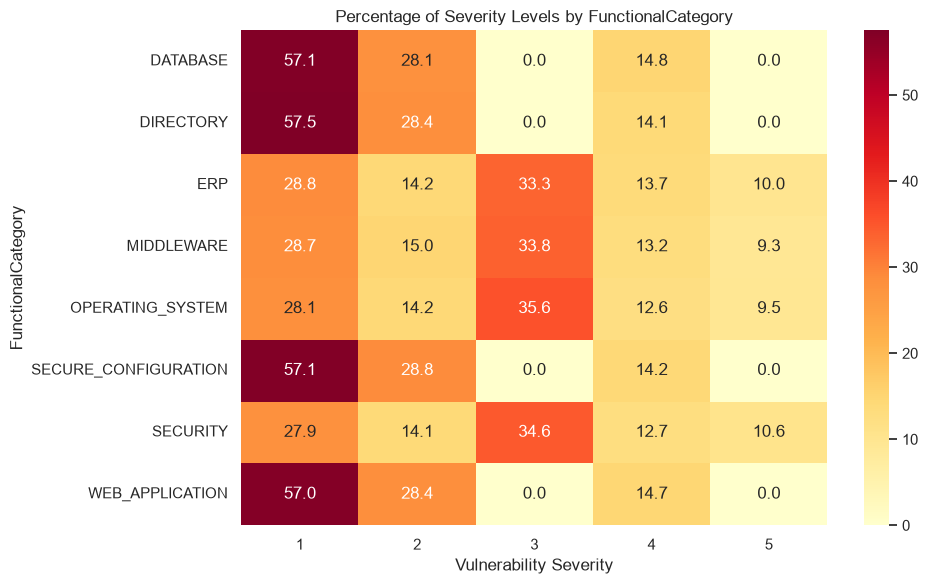

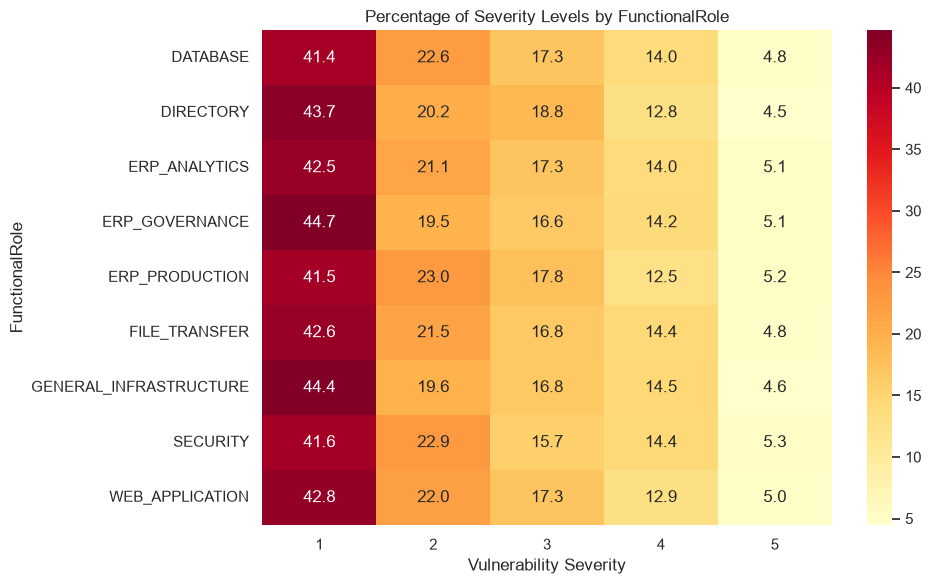

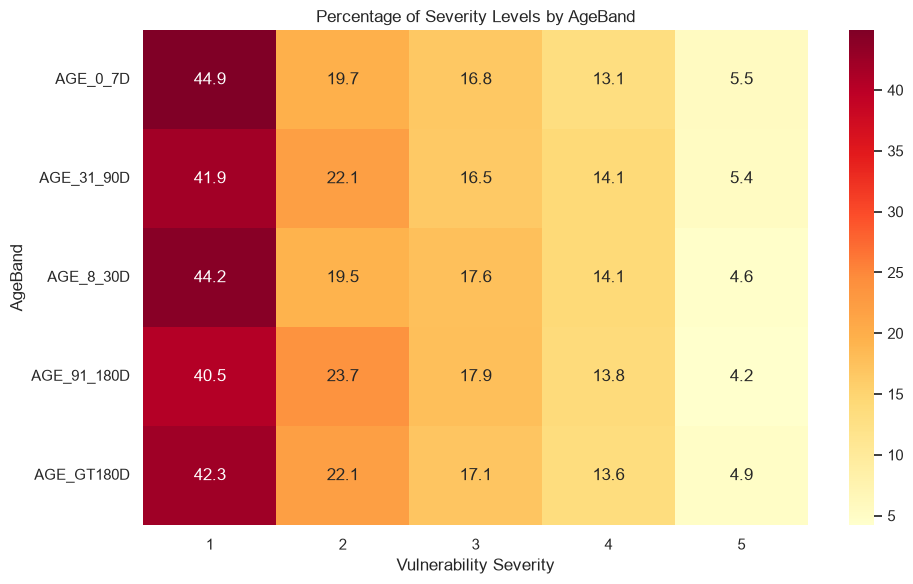

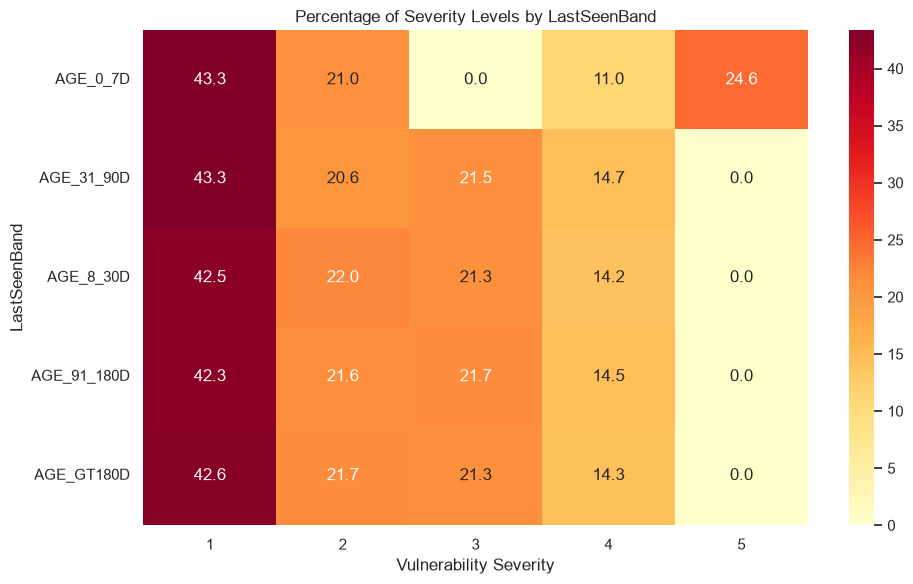

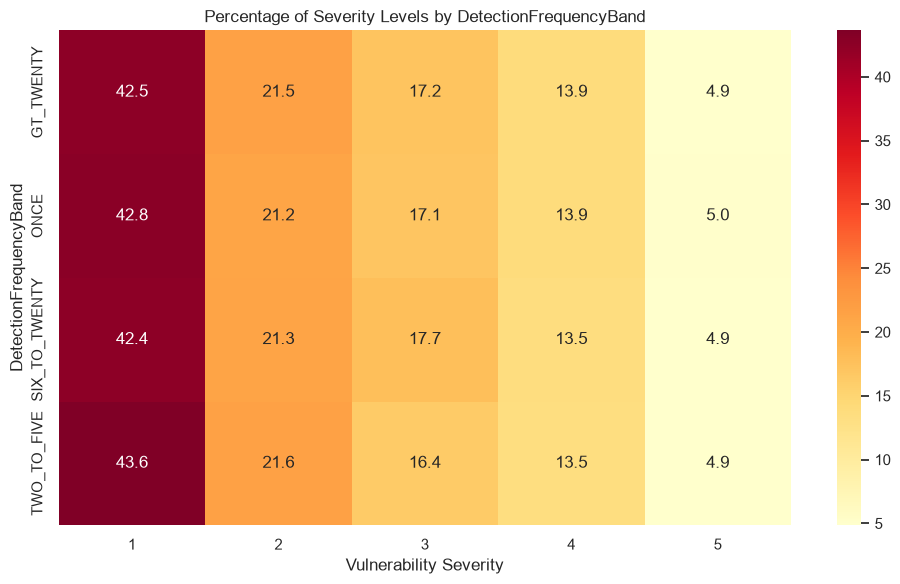

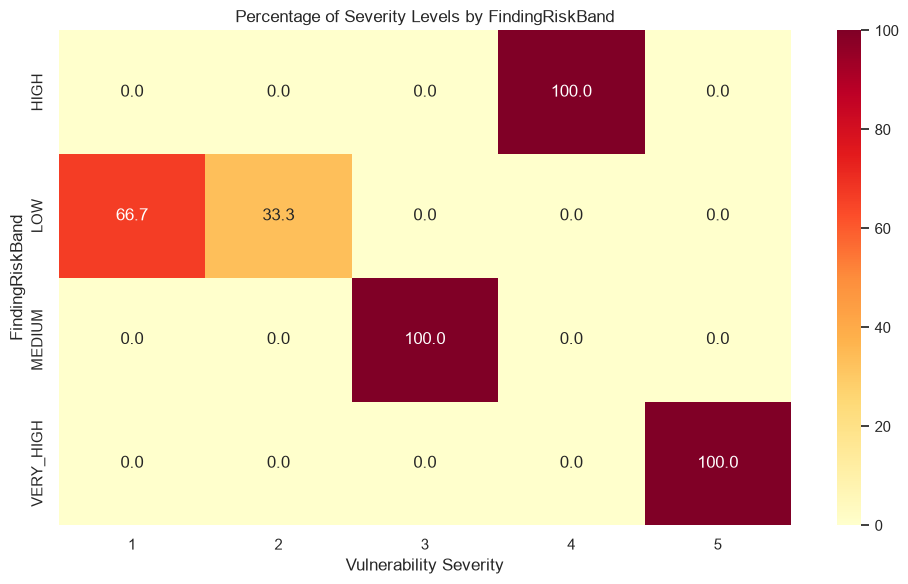

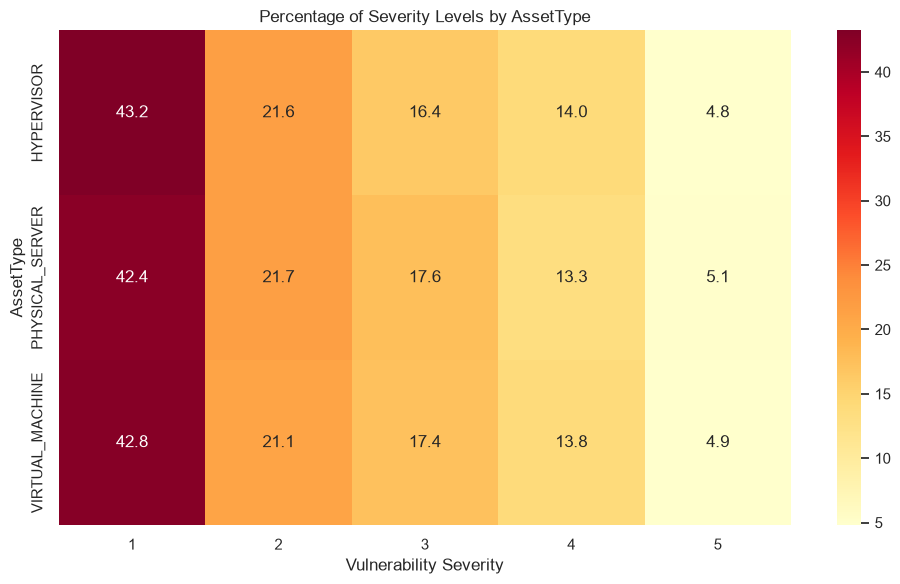

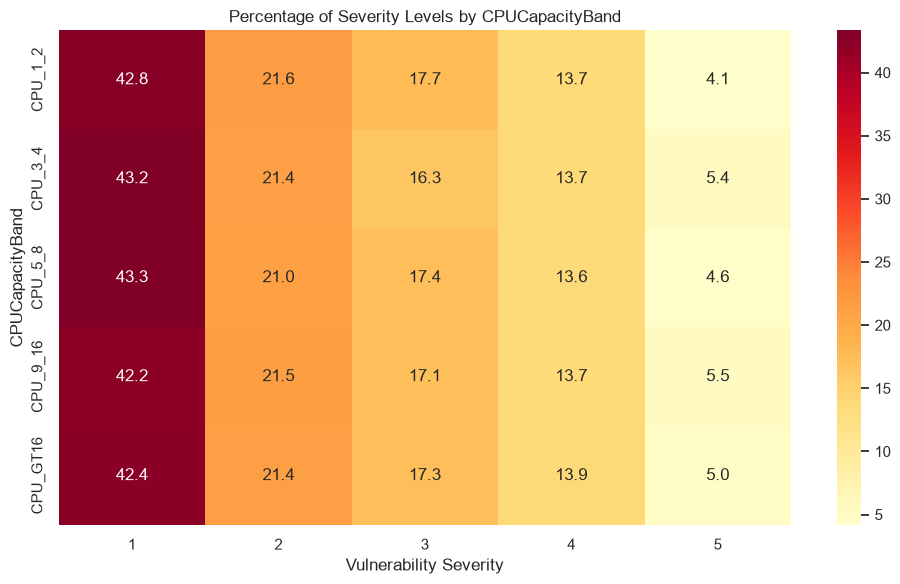

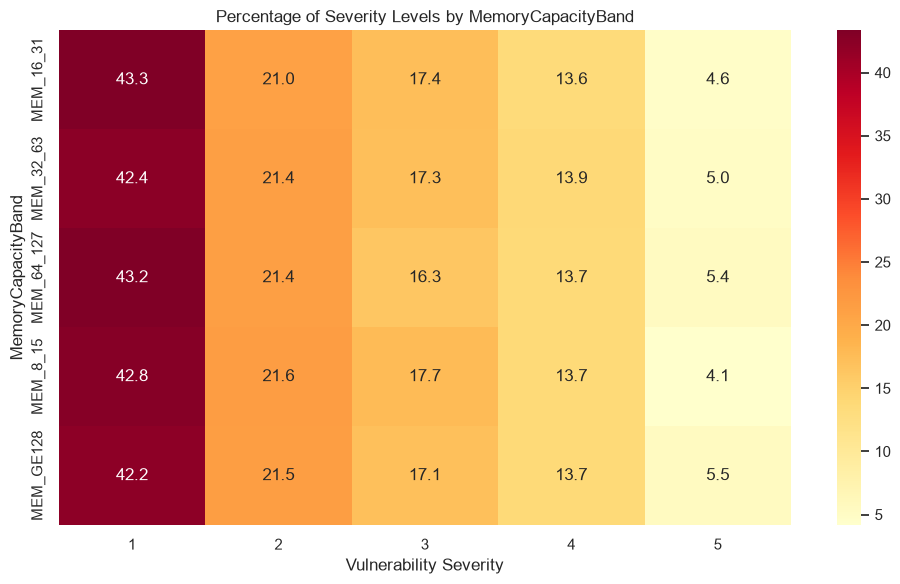

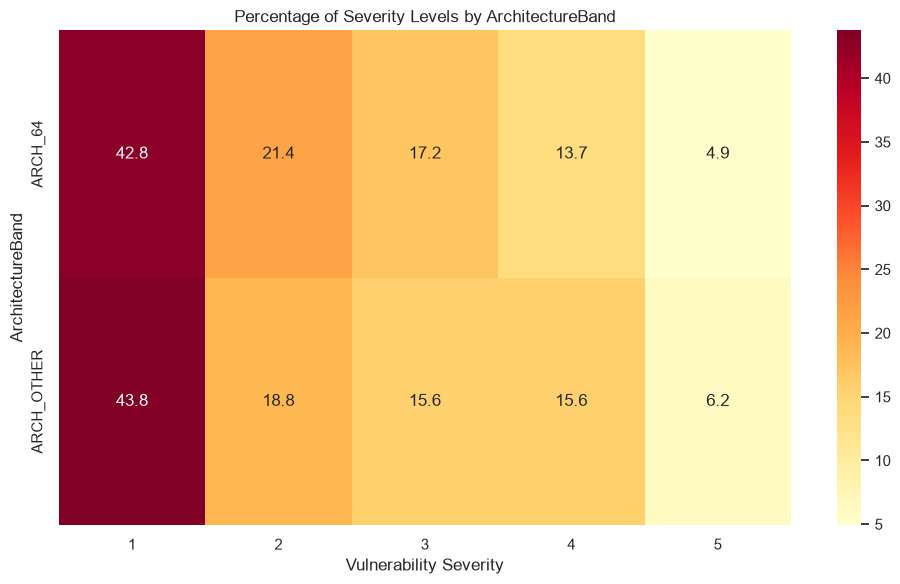

In [5]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df_merged = pd.merge(df_s, df_v, on="ServerID")

# List of categories to compare
features_to_compare = [
    "OSFamily",
    "AssetCriticality",
    "FunctionalCategory",
    "FunctionalRole",
    "AgeBand",
    "LastSeenBand",
    "DetectionFrequencyBand",
    "FindingRiskBand",
    "AssetType",
    "CPUCapacityBand",
    "MemoryCapacityBand",
    "ArchitectureBand",
]
# Iterate ta hrough each feature and plot its heatmap
for feature in features_to_compare:
    # Safely skip if the column doesn't exist in the merged dataframe
    if feature not in df_merged.columns:
        print(f"Warning: '{feature}' not found in the DataFrame. Skipping.")
        continue

    # Create a cross-tabulation table
    cross_tab = (
        pd.crosstab(df_merged[feature], df_merged["Severity"], normalize="index")
        * 100
    )

    # Plot it as a heatmap to instantly see hotspots
    plt.figure(figsize=(10, 6))
    sns.heatmap(cross_tab, annot=True, cmap="YlOrRd", fmt=".1f")

    # Dynamically set titles and labels based on the current feature
    plt.title(f"Percentage of Severity Levels by {feature}")
    plt.ylabel(feature)
    plt.xlabel("Vulnerability Severity")

    plt.tight_layout()  # Prevents labels from getting cut off
    plt.show()
